# Classificação de Dígitos no SVHN

**Integrantes:** João Pedro Santos de Brito, Samyr Arruda Villanova e Valber Oliveira da Conceição

Trabalho final de Inteligência Artificial. Treinamos um classificador linear, várias MLPs e, para comparação, uma
CNN no SVHN. A primeira célula grava o `svhn_lib.py`, com as funções usadas no resto do notebook.

Para rodar, basta executar todas as células. Em CPU leva cerca de 10 h; no Colab dá para ligar a GPU.

**Como avaliamos**
- Usamos os splits `train` (73.257 imagens) e `test` (26.032) do `torchvision.datasets.SVHN`.
- Separamos 10% do `train` para validação, com a semente 42.
- Todas as escolhas (experimento, melhor época, raio da predição) são feitas pela validação. O teste só mostra o
  resultado de cada experimento.
- O modelo final tem que ser uma MLP, então a CNN (E12 e E13) fica só como comparação.
- No fim, o modelo escolhido é treinado de novo com o `train` inteiro.
- O conjunto adicional só é usado na última seção, para gerar as predições.
- A semente é 42 em tudo, então rodar de novo dá os mesmos números.

## 0. Implementação (`svhn_lib.py`)

Partimos do código das aulas (classificador linear e MLP) e adaptamos para o SVHN. O arquivo tem:

- `load_svhn`: carrega `train` e `test` como tensores `uint8` no formato (N, 3, 32, 32). Se os `.mat` de Stanford
  não estiverem na pasta, lê os mesmos dados de uma cópia em parquet (`data_hf/`).
- `split_train_val`: separa treino e validação com a semente.
- `compute_norm_stats`: média e desvio de cada canal, calculados só no treino. As somas são feitas com inteiros
  porque, em float32, o resultado mudava na 7ª casa decimal entre execuções, e isso já mudava o treino.
- `preprocess` e `per_image_norm`: passam os pixels para [0, 1] e normalizam por canal; o `per_image_norm`
  normaliza cada imagem pela própria média e desvio.
- `random_shift` e `random_affine`: augmentation (translação; rotação e escala). Não usamos espelhamento porque
  ele muda alguns dígitos.
- `LinearClassifier`, `MLP` e `CNN`: os modelos. Na `MLP`, cada camada oculta é Linear → BatchNorm (opcional) →
  ReLU → Dropout (opcional).
- `train_model`: laço de treino. Guarda loss e acurácia de treino e validação a cada época e, no fim, volta para os
  pesos da época com a melhor acurácia de validação. Sem validação (treino final), fica com a última época.
- `evaluate`, `predict` e `predict_tta`: avaliação e predição. O `predict_tta` faz a média das probabilidades da
  imagem deslocada alguns pixels (seção 5).
- `load_image_folder` e `write_results`: leem as imagens de uma pasta em ordem do nome e gravam uma predição por
  linha.

A célula abaixo grava o `svhn_lib.py`, que é importado nas células seguintes.

In [1]:
%%writefile svhn_lib.py
import copy
import math
import os
import random
import re
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
N_CLASSES = 10
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tif", ".tiff", ".webp"}


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device() -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_parquet_split(path):
    import io

    import pandas as pd
    from PIL import Image

    df = pd.read_parquet(path)
    X = np.stack([np.asarray(Image.open(io.BytesIO(im["bytes"])).convert("RGB"), dtype=np.uint8)
                  for im in df["image"]]).transpose(0, 3, 1, 2)
    return torch.from_numpy(np.ascontiguousarray(X)), torch.tensor(df["label"].to_numpy(), dtype=torch.int64)


def load_svhn(root: str = "data", hf_root: str = "data_hf"):
    import torchvision

    out = []
    for split in ("train", "test"):
        pq = Path(hf_root) / f"{split}.parquet"
        if not (Path(root) / f"{split}_32x32.mat").exists() and pq.exists():
            out.append(load_parquet_split(pq))
            continue
        ds = torchvision.datasets.SVHN(root=root, split=split, download=True)
        X = torch.from_numpy(ds.data)
        y = torch.from_numpy(ds.labels.astype(np.int64))
        out.append((X, y))
    return out[0], out[1]


def split_train_val(n: int, val_frac: float = 0.1, seed: int = SEED):
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_val = int(round(n * val_frac))
    return perm[n_val:], perm[:n_val]


def compute_norm_stats(X: torch.Tensor):
    means, stds = [], []
    for c in range(X.shape[1]):
        xc = X[:, c].to(torch.int64)
        n, s, ss = xc.numel(), int(xc.sum()), int((xc * xc).sum())
        means.append(s / n / 255.0)
        stds.append(((ss * n - s * s) / (n * (n - 1))) ** 0.5 / 255.0)
    return torch.tensor(means, dtype=torch.float32), torch.tensor(stds, dtype=torch.float32)


def preprocess(X: torch.Tensor, mean=None, std=None) -> torch.Tensor:
    Xf = X.float() / 255.0
    if mean is not None:
        Xf = (Xf - mean.view(1, -1, 1, 1)) / std.view(1, -1, 1, 1)
    return Xf


def per_image_norm(Xf: torch.Tensor, eps: float = 1e-3) -> torch.Tensor:
    m = Xf.mean(dim=(1, 2, 3), keepdim=True)
    s = Xf.std(dim=(1, 2, 3), keepdim=True)
    return (Xf - m) / (s + eps)


def random_affine(x: torch.Tensor, max_shift: int, max_rot: float, max_scale: float,
                  gen: torch.Generator) -> torch.Tensor:
    B = len(x)
    ang = (torch.rand(B, generator=gen) * 2 - 1) * math.radians(max_rot)
    sc = 1 + (torch.rand(B, generator=gen) * 2 - 1) * max_scale
    t = (torch.rand(B, 2, generator=gen) * 2 - 1) * (2 * max_shift / x.shape[-1])
    theta = torch.zeros(B, 2, 3)
    theta[:, 0, 0] = torch.cos(ang) / sc
    theta[:, 0, 1] = -torch.sin(ang) / sc
    theta[:, 1, 0] = torch.sin(ang) / sc
    theta[:, 1, 1] = torch.cos(ang) / sc
    theta[:, :, 2] = t
    grid = F.affine_grid(theta.to(x.device), list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=False)


def shift_fixed(x: torch.Tensor, dx: int, dy: int) -> torch.Tensor:
    if dx == 0 and dy == 0:
        return x
    p = max(abs(dx), abs(dy))
    H, W = x.shape[-2:]
    xp = F.pad(x, (p, p, p, p), mode="replicate")
    return xp[:, :, p + dy:p + dy + H, p + dx:p + dx + W]


def random_shift(x: torch.Tensor, max_shift: int, gen: torch.Generator) -> torch.Tensor:
    if max_shift <= 0:
        return x
    B, C, H, W = x.shape
    p = max_shift
    xp = F.pad(x, (p, p, p, p), mode="replicate")
    dx = torch.randint(0, 2 * p + 1, (B,), generator=gen).to(x.device)
    dy = torch.randint(0, 2 * p + 1, (B,), generator=gen).to(x.device)
    rows = dy[:, None] + torch.arange(H, device=x.device)
    cols = dx[:, None] + torch.arange(W, device=x.device)
    b = torch.arange(B, device=x.device)[:, None, None]
    out = xp.permute(0, 2, 3, 1)[b, rows[:, :, None], cols[:, None, :]]
    return out.permute(0, 3, 1, 2).contiguous()


class LinearClassifier(nn.Module):
    def __init__(self, in_features: int = 3 * 32 * 32, n_classes: int = N_CLASSES):
        super().__init__()
        self.fc = nn.Linear(in_features, n_classes)

    def forward(self, x):
        return self.fc(x.flatten(1))


class MLP(nn.Module):
    def __init__(self, hidden_sizes, dropout: float = 0.0, batchnorm: bool = False,
                 in_features: int = 3 * 32 * 32, n_classes: int = N_CLASSES):
        super().__init__()
        self.config = dict(hidden_sizes=list(hidden_sizes), dropout=dropout, batchnorm=batchnorm)
        layers, prev = [], in_features
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.flatten(1))


def _conv_bn(cin, cout):
    return [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU()]


class CNN(nn.Module):
    def __init__(self, dropout: float = 0.3, n_classes: int = N_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            *_conv_bn(3, 32), *_conv_bn(32, 32), nn.MaxPool2d(2),
            *_conv_bn(32, 64), *_conv_bn(64, 64), nn.MaxPool2d(2),
            *_conv_bn(64, 128), *_conv_bn(128, 128), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@torch.no_grad()
def evaluate(model, X, y, batch_size: int = 2048, device=None):
    device = device or next(model.parameters()).device
    model.eval()
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
        out = model(xb)
        total_loss += F.cross_entropy(out, yb, reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)


def train_model(model, data, epochs: int, batch_size: int, lr: float,
                optimizer: str = "adam", weight_decay: float = 0.0,
                scheduler: str | None = None, augment_shift: int = 0,
                augment_rot: float = 0.0, augment_scale: float = 0.0,
                seed: int = SEED, device=None, verbose: bool = True):
    device = device or get_device()
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model.to(device)

    if optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    else:
        raise ValueError(f"otimizador desconhecido: {optimizer}")
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if scheduler == "cosine" else None

    X_tr, y_tr = data["X_train"], data["y_train"]
    has_val = "X_val" in data
    n = len(X_tr)
    onecycle = None
    if scheduler == "onecycle":
        onecycle = torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=lr, total_steps=epochs * math.ceil(n / batch_size), pct_start=0.1)
    elif scheduler not in (None, "cosine"):
        raise ValueError(f"scheduler desconhecido: {scheduler}")
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "epoch_time")}
    best_acc, best_state, best_epoch = -1.0, None, -1

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        perm = torch.randperm(n, generator=gen)
        run_loss, run_correct = 0.0, 0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb = X_tr[idx]
            if augment_rot or augment_scale:
                xb = random_affine(xb, augment_shift, augment_rot, augment_scale, gen)
            elif augment_shift:
                xb = random_shift(xb, augment_shift, gen)
            xb, yb = xb.to(device), y_tr[idx].to(device)

            out = model(xb)
            loss = F.cross_entropy(out, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            if onecycle:
                onecycle.step()

            run_loss += loss.item() * len(idx)
            run_correct += (out.argmax(1) == yb).sum().item()
        if sched:
            sched.step()

        hist["train_loss"].append(run_loss / n)
        hist["train_acc"].append(run_correct / n)
        msg = (f"época {epoch + 1:2d}/{epochs} | treino loss {hist['train_loss'][-1]:.4f} "
               f"acc {hist['train_acc'][-1]:.4f}")
        if has_val:
            val_loss, val_acc = evaluate(model, data["X_val"], data["y_val"], device=device)
            hist["val_loss"].append(val_loss)
            hist["val_acc"].append(val_acc)
            msg += f" | val loss {val_loss:.4f} acc {val_acc:.4f}"
            if val_acc > best_acc:
                best_acc, best_epoch = val_acc, epoch
                best_state = copy.deepcopy(model.state_dict())
        hist["epoch_time"].append(time.time() - t0)
        if verbose:
            print(f"{msg} | {hist['epoch_time'][-1]:.1f}s")

    if has_val:
        model.load_state_dict(best_state)
        hist["best_epoch"], hist["best_val_acc"] = best_epoch, best_acc
    else:
        hist["best_epoch"], hist["best_val_acc"] = epochs - 1, None
    return hist


def confusion_matrix(y_true, y_pred, n_classes: int = N_CLASSES) -> torch.Tensor:
    idx = y_true.long() * n_classes + y_pred.long()
    return torch.bincount(idx, minlength=n_classes * n_classes).view(n_classes, n_classes)


@torch.no_grad()
def predict(model, X, batch_size: int = 2048, device=None) -> torch.Tensor:
    device = device or next(model.parameters()).device
    model.eval()
    preds = [model(X[i:i + batch_size].to(device)).argmax(1).cpu() for i in range(0, len(X), batch_size)]
    return torch.cat(preds).long()


@torch.no_grad()
def predict_proba(model, X, tta_radius: int = 0, batch_size: int = 2048, device=None) -> torch.Tensor:
    device = device or next(model.parameters()).device
    model.eval()
    r = tta_radius
    out = []
    for i in range(0, len(X), batch_size):
        xb = X[i:i + batch_size].to(device)
        p = torch.zeros(len(xb), N_CLASSES, device=device)
        for dy in range(-r, r + 1):
            for dx in range(-r, r + 1):
                p += F.softmax(model(shift_fixed(xb, dx, dy)), dim=1)
        out.append((p / (2 * r + 1) ** 2).cpu())
    return torch.cat(out)


def predict_tta(model, X, tta_radius: int = 0, batch_size: int = 2048, device=None) -> torch.Tensor:
    return predict_proba(model, X, tta_radius, batch_size, device).argmax(1).long()


def plot_history(hist, title: str = "", path=None):
    import matplotlib.pyplot as plt

    ep = range(1, len(hist["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    a1.plot(ep, hist["train_loss"], label="treino")
    a1.set(xlabel="época", ylabel="loss (cross-entropy)", title="Loss")
    a2.plot(ep, hist["train_acc"], label="treino")
    if hist["val_loss"]:
        a1.plot(ep, hist["val_loss"], label="validação")
        a2.plot(ep, hist["val_acc"], label="validação")
        a2.axvline(hist["best_epoch"] + 1, ls=":", c="gray", label="melhor época (val)")
    a2.set(xlabel="época", ylabel="acurácia", title="Acurácia")
    from matplotlib.ticker import MaxNLocator
    for a in (a1, a2):
        a.xaxis.set_major_locator(MaxNLocator(integer=True))
        a.grid(alpha=0.3)
        a.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=130)
    return fig


def natural_sort_key(name: str):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(name))]


def load_image_folder(folder):
    from PIL import Image

    folder = Path(folder)
    names = sorted((p.name for p in folder.iterdir()
                    if p.is_file() and p.suffix.lower() in IMG_EXTS), key=natural_sort_key)
    arrs = []
    for nm in names:
        with Image.open(folder / nm) as im:
            im = im.convert("RGB")
            if im.size != (32, 32):
                im = im.resize((32, 32), Image.BILINEAR)
            arrs.append(np.asarray(im, dtype=np.uint8).transpose(2, 0, 1))
    X = torch.from_numpy(np.stack(arrs)) if arrs else torch.empty(0, 3, 32, 32, dtype=torch.uint8)
    return names, X


def write_results(preds, path) -> None:
    vals = [int(v) for v in (preds.tolist() if hasattr(preds, "tolist") else preds)]
    if any(v < 0 or v > 9 for v in vals):
        raise ValueError("predições devem ser inteiros entre 0 e 9")
    Path(path).write_text("".join(f"{v}\n" for v in vals))

Overwriting svhn_lib.py


In [2]:
import os, sys, json, time, importlib
import svhn_lib
importlib.reload(svhn_lib)
import svhn_lib as L
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
L.set_seed(SEED)
device = L.get_device()
os.makedirs('resultados', exist_ok=True)
os.makedirs('pesos', exist_ok=True)
print('device:', device, '| torch', torch.__version__, '| threads', torch.get_num_threads())

device: cpu | torch 2.15.0+cpu | threads 12


## 1. Dados

In [3]:
(X_all, y_all), (X_test_u8, y_test) = L.load_svhn('data')
idx_tr, idx_va = L.split_train_val(len(X_all), val_frac=0.1, seed=SEED)
X_tr_u8, y_train = X_all[idx_tr], y_all[idx_tr]
X_va_u8, y_val = X_all[idx_va], y_all[idx_va]
print('treino   :', tuple(X_tr_u8.shape))
print('validação:', tuple(X_va_u8.shape))
print('teste    :', tuple(X_test_u8.shape))

treino   : (65931, 3, 32, 32)
validação: (7326, 3, 32, 32)
teste    : (26032, 3, 32, 32)


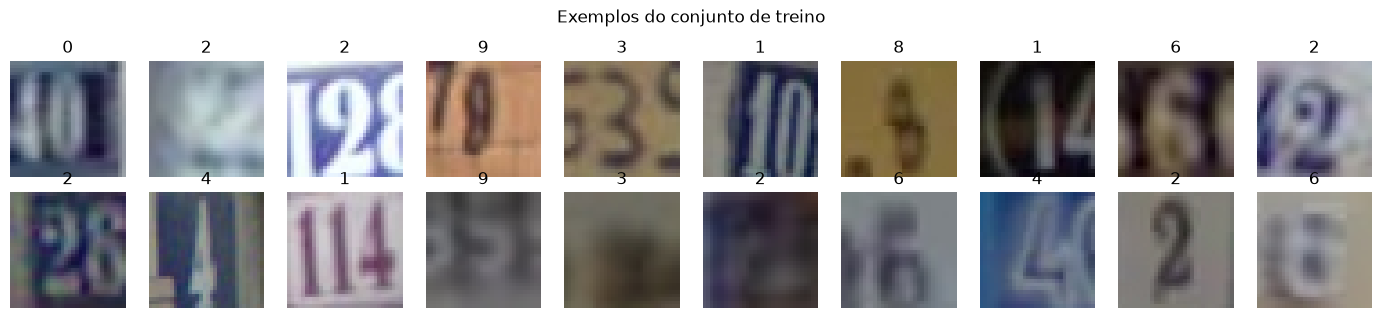

,treino,validação,teste
dígito,,,
0,4506,442,1744
1,12418,1443,5099
2,9475,1110,4149
3,7639,858,2882
4,6717,741,2523
5,6216,666,2384
6,5163,564,1977
7,5068,527,2019
8,4538,507,1660


In [4]:
fig, ax = plt.subplots(2, 10, figsize=(14, 3.2))
for i, a in enumerate(ax.flat):
    a.imshow(X_tr_u8[i].permute(1, 2, 0)); a.set_title(int(y_train[i])); a.axis('off')
plt.suptitle('Exemplos do conjunto de treino'); plt.tight_layout(); plt.savefig('resultados/exemplos.png', dpi=120); plt.show()

dist = pd.DataFrame({s: np.bincount(y.numpy(), minlength=10) for s, y in
                     [('treino', y_train), ('validação', y_val), ('teste', y_test)]})
dist.index.name = 'dígito'; dist

**Pré-processamento.** Usamos três versões dos dados:
- `bruto`: pixels em [0, 1], como no notebook da aula.
- `norm`: subtrai a média e divide pelo desvio de cada canal de cor, calculados só no treino (como no slide de
  pré-processamento). Validação e teste usam os mesmos valores.
- `norm_img`: a `norm` seguida de uma normalização por imagem (cada imagem pela própria média e desvio). Só é usada
  a partir do E16.

In [5]:
mean, std = L.compute_norm_stats(X_tr_u8)
print('média por canal:', mean.numpy().round(4), '| desvio:', std.numpy().round(4))

DATA = {
    'bruto': dict(X_train=L.preprocess(X_tr_u8), y_train=y_train,
                  X_val=L.preprocess(X_va_u8), y_val=y_val,
                  X_test=L.preprocess(X_test_u8), y_test=y_test),
    'norm':  dict(X_train=L.preprocess(X_tr_u8, mean, std), y_train=y_train,
                  X_val=L.preprocess(X_va_u8, mean, std), y_val=y_val,
                  X_test=L.preprocess(X_test_u8, mean, std), y_test=y_test),
}
DATA['norm_img'] = {k: (L.per_image_norm(v) if k.startswith('X_') else v) for k, v in DATA['norm'].items()}

média por canal: [0.4376 0.4437 0.4727] | desvio: [0.1979 0.2009 0.1969]


**Checagem de sanidade (aula de loss).** Com os pesos aleatórios do início, a loss deve ficar perto de
$\ln 10 \approx 2{,}303$ e a acurácia perto de 10%.

In [6]:
L.set_seed(SEED)
for nome, m in [('Linear', L.LinearClassifier()), ('MLP 2×500', L.MLP([500, 500])), ('CNN', L.CNN())]:
    loss0, acc0 = L.evaluate(m, DATA['norm']['X_val'], y_val)
    print(f'{nome:10s} loss inicial = {loss0:.3f} (ln 10 = {np.log(10):.3f}) | acurácia inicial = {acc0:.3f}')

Linear     loss inicial = 2.466 (ln 10 = 2.303) | acurácia inicial = 0.095
MLP 2×500  loss inicial = 2.315 (ln 10 = 2.303) | acurácia inicial = 0.083


CNN        loss inicial = 2.302 (ln 10 = 2.303) | acurácia inicial = 0.072


## 2. Função que roda um experimento

A função `run` treina o modelo, avalia no teste com os pesos da melhor época na validação e salva o histórico
(`resultados/*.json`), as curvas (`resultados/*.png`) e os pesos (`pesos/*.pt`).

Obs.: a acurácia de treino é a média da época, com dropout e augmentation ligados. Por isso ela às vezes fica abaixo
da de validação.

In [7]:
RESULTS, REGISTRY = [], {}

def run(exp_id, nome, modificacao, make_model, dados='norm', pai=None, **train_kw):
    print(f'=== E{exp_id}: {nome} ===')
    REGISTRY[exp_id] = (make_model, dados, train_kw)
    L.set_seed(SEED)
    model = make_model()
    data = DATA[dados]
    t0 = time.time()
    hist = L.train_model(model, data, seed=SEED, device=device, **train_kw)
    test_loss, test_acc = L.evaluate(model, data['X_test'], data['y_test'], device=device)
    b = hist['best_epoch']
    row = dict(exp=exp_id, nome=nome, modificacao=modificacao, dados=dados, pai=pai,
               params=L.count_params(model), epocas=train_kw['epochs'], melhor_epoca=b + 1,
               train_loss=hist['train_loss'][b], val_loss=hist['val_loss'][b],
               train_acc=hist['train_acc'][b], val_acc=hist['val_acc'][b],
               test_acc=test_acc, tempo_min=(time.time() - t0) / 60,
               config={k: v for k, v in train_kw.items()})
    RESULTS.append(row)
    torch.save({'state_dict': model.state_dict(), 'row': row}, f'pesos/E{exp_id}.pt')
    with open(f'resultados/E{exp_id}.json', 'w') as f:
        json.dump({'row': row, 'hist': hist}, f, indent=1)
    L.plot_history(hist, f'E{exp_id} — {nome}', f'resultados/E{exp_id}_curvas.png'); plt.show()
    print(f"melhor época {b+1}: train_loss={row['train_loss']:.4f} val_loss={row['val_loss']:.4f} | "
          f"train_acc={row['train_acc']:.4f} val_acc={row['val_acc']:.4f} | test_acc={test_acc:.4f} | {row['tempo_min']:.1f} min")
    return model, hist

## 3. Experimentos

Cada experimento muda **um fator** em relação a um experimento anterior (o "pai", indicado em cada um), para que a
melhora ou a piora possa ser atribuída a esse fator. Quando duas ou mais alternativas são comparadas (taxa de
aprendizado, tamanho do batch), o código segue automaticamente com a de **maior acurácia de validação**.

### E1 — Classificador linear
`logits = x·W + b` sobre os 3072 pixels normalizados, com cross-entropy (softmax) e regularização L2
(`weight_decay`), treinado por gradiente descendente em mini-batches com momentum. É o classificador linear da aula,
agora com `nn.Linear`.

=== E1: Classificador linear ===


época  1/20 | treino loss 2.2920 acc 0.1582 | val loss 2.2603 acc 0.1996 | 0.6s


época  2/20 | treino loss 2.2345 acc 0.2213 | val loss 2.2262 acc 0.2322 | 0.6s


época  3/20 | treino loss 2.2113 acc 0.2374 | val loss 2.2112 acc 0.2502 | 0.6s


época  4/20 | treino loss 2.1984 acc 0.2456 | val loss 2.2006 acc 0.2584 | 0.6s


época  5/20 | treino loss 2.1895 acc 0.2517 | val loss 2.1965 acc 0.2562 | 0.6s


... (11 outputs left out)

época 17/20 | treino loss 2.1477 acc 0.2785 | val loss 2.1608 acc 0.2812 | 0.6s


época 18/20 | treino loss 2.1461 acc 0.2777 | val loss 2.1579 acc 0.2806 | 0.6s


época 19/20 | treino loss 2.1442 acc 0.2795 | val loss 2.1536 acc 0.2883 | 0.6s


época 20/20 | treino loss 2.1427 acc 0.2818 | val loss 2.1551 acc 0.2853 | 0.6s


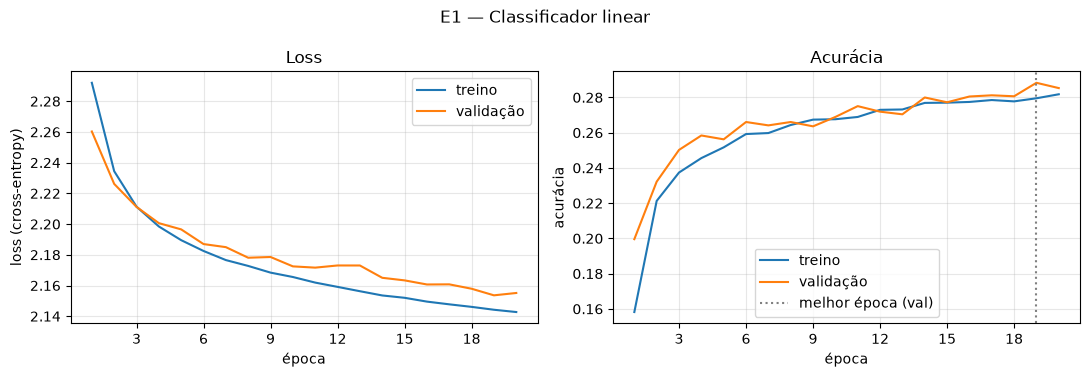

melhor época 19: train_loss=2.1442 val_loss=2.1536 | train_acc=0.2795 val_acc=0.2883 | test_acc=0.2402 | 0.2 min


In [8]:
run(1, 'Classificador linear', 'Linear 3072→10, SGD + L2',
    lambda: L.LinearClassifier(), dados='norm',
    epochs=20, batch_size=128, lr=1e-4, optimizer='sgd', weight_decay=1e-4);

### E2 — MLP baseline (código da aula)
A MLP do notebook da aula, sem alterações: 2 camadas ocultas de 500 neurônios, ReLU, Adam com lr = 1e-3, batch 100
e entrada apenas em [0, 1].

=== E2: MLP baseline ===


época  1/25 | treino loss 2.1650 acc 0.2092 | val loss 2.0044 acc 0.2554 | 8.1s


época  2/25 | treino loss 1.8923 acc 0.3130 | val loss 1.6974 acc 0.4233 | 30.2s


época  3/25 | treino loss 1.5688 acc 0.4610 | val loss 1.5051 acc 0.4840 | 33.2s


época  4/25 | treino loss 1.4573 acc 0.5023 | val loss 1.4219 acc 0.5235 | 32.0s


época  5/25 | treino loss 1.4096 acc 0.5223 | val loss 1.4742 acc 0.5059 | 30.4s


... (16 outputs left out)

época 22/25 | treino loss 1.2772 acc 0.5811 | val loss 1.3142 acc 0.5684 | 29.0s


época 23/25 | treino loss 1.2736 acc 0.5820 | val loss 1.3306 acc 0.5620 | 29.3s


época 24/25 | treino loss 1.2701 acc 0.5857 | val loss 1.2923 acc 0.5786 | 30.3s


época 25/25 | treino loss 1.2677 acc 0.5844 | val loss 1.2986 acc 0.5710 | 30.2s


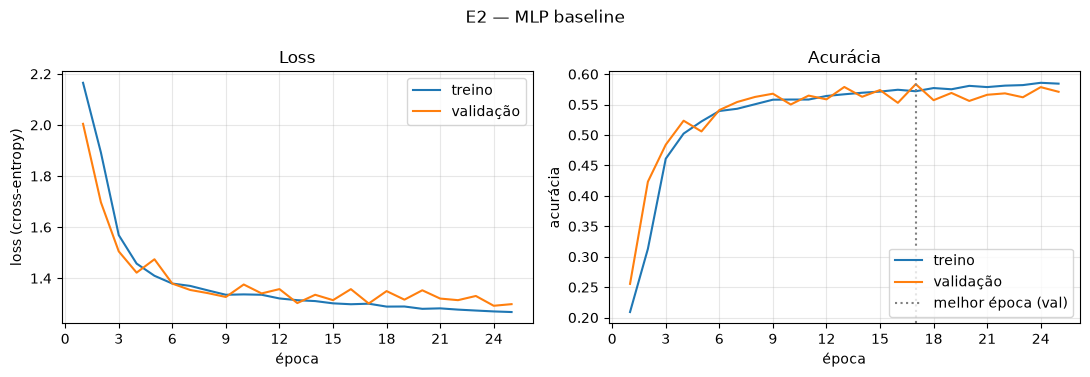

melhor época 17: train_loss=1.3004 val_loss=1.3011 | train_acc=0.5719 val_acc=0.5835 | test_acc=0.5501 | 12.2 min


In [9]:
run(2, 'MLP baseline', 'MLP 2×500, entrada em [0,1]',
    lambda: L.MLP([500, 500]), dados='bruto', pai=1,
    epochs=25, batch_size=100, lr=1e-3);

### E3 — E2 + normalização por canal

=== E3: MLP + normalização ===


época  1/25 | treino loss 1.1840 acc 0.6211 | val loss 0.9350 acc 0.7174 | 7.4s


época  2/25 | treino loss 0.8185 acc 0.7501 | val loss 0.7940 acc 0.7563 | 8.9s


época  3/25 | treino loss 0.7042 acc 0.7841 | val loss 0.7337 acc 0.7804 | 9.6s


época  4/25 | treino loss 0.6421 acc 0.8029 | val loss 0.7024 acc 0.7894 | 9.8s


época  5/25 | treino loss 0.5904 acc 0.8209 | val loss 0.6804 acc 0.7995 | 10.2s


... (16 outputs left out)

época 22/25 | treino loss 0.3198 acc 0.8995 | val loss 0.8351 acc 0.8249 | 10.9s


época 23/25 | treino loss 0.3109 acc 0.9022 | val loss 0.8443 acc 0.8302 | 10.8s


época 24/25 | treino loss 0.3039 acc 0.9044 | val loss 0.8434 acc 0.8204 | 11.3s


época 25/25 | treino loss 0.2999 acc 0.9050 | val loss 0.8777 acc 0.8215 | 10.2s


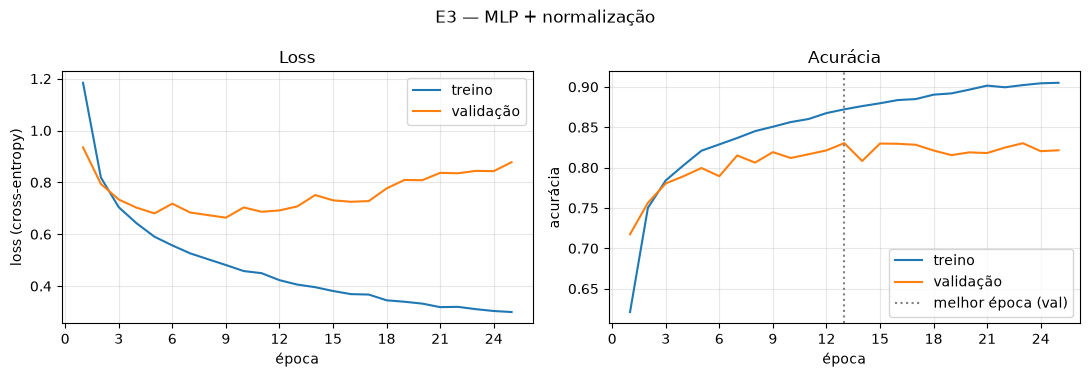

melhor época 13: train_loss=0.4058 val_loss=0.7073 | train_acc=0.8722 val_acc=0.8303 | test_acc=0.7948 | 4.4 min


In [10]:
run(3, 'MLP + normalização', 'E2 + normalização (média/desvio por canal)',
    lambda: L.MLP([500, 500]), dados='norm', pai=2,
    epochs=25, batch_size=100, lr=1e-3);

### E4 e E5 — Taxa de aprendizado (10× maior e 10× menor que a do E3)
Mesmo modelo do E3, mudando só a taxa de aprendizado: 1e-2 (E4) e 1e-4 (E5).

=== E4: MLP lr alta (1e-2) ===


época  1/25 | treino loss 2.5749 acc 0.1853 | val loss 2.2263 acc 0.1970 | 9.8s


época  2/25 | treino loss 2.2420 acc 0.1883 | val loss 2.2255 acc 0.1970 | 13.0s


época  3/25 | treino loss 2.2385 acc 0.1883 | val loss 2.2251 acc 0.1970 | 16.5s


época  4/25 | treino loss 2.2385 acc 0.1883 | val loss 2.2260 acc 0.1970 | 31.2s


época  5/25 | treino loss 2.2386 acc 0.1883 | val loss 2.2258 acc 0.1970 | 32.0s


... (16 outputs left out)

época 22/25 | treino loss 2.2386 acc 0.1883 | val loss 2.2249 acc 0.1970 | 36.3s


época 23/25 | treino loss 2.2386 acc 0.1883 | val loss 2.2249 acc 0.1970 | 34.0s


época 24/25 | treino loss 2.2386 acc 0.1883 | val loss 2.2261 acc 0.1970 | 31.4s


época 25/25 | treino loss 2.2384 acc 0.1883 | val loss 2.2255 acc 0.1970 | 32.1s


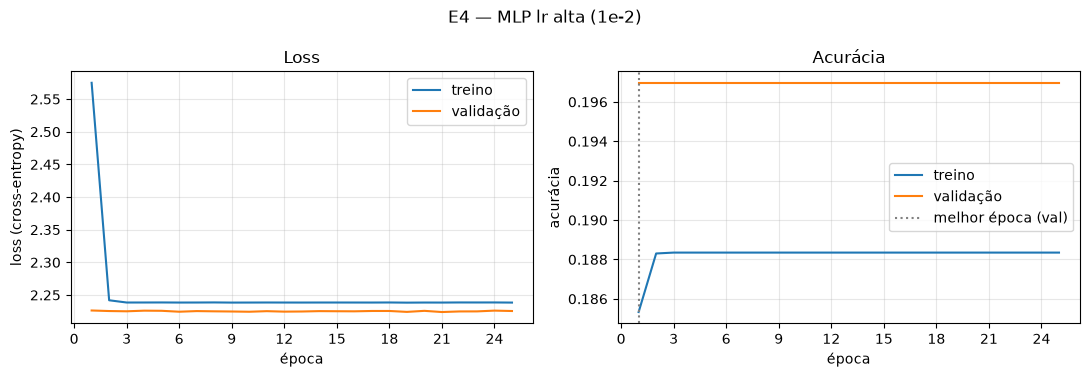

melhor época 1: train_loss=2.5749 val_loss=2.2263 | train_acc=0.1853 val_acc=0.1970 | test_acc=0.1959 | 12.0 min


In [11]:
run(4, 'MLP lr alta (1e-2)', 'E3 com lr = 1e-2',
    lambda: L.MLP([500, 500]), dados='norm', pai=3,
    epochs=25, batch_size=100, lr=1e-2);

=== E5: MLP lr baixa (1e-4) ===


época  1/25 | treino loss 1.3127 acc 0.5860 | val loss 0.9418 acc 0.7195 | 9.9s


época  2/25 | treino loss 0.8324 acc 0.7502 | val loss 0.7866 acc 0.7643 | 11.2s


época  3/25 | treino loss 0.6989 acc 0.7925 | val loss 0.6802 acc 0.8011 | 10.3s


época  4/25 | treino loss 0.6206 acc 0.8163 | val loss 0.6503 acc 0.8082 | 9.7s


época  5/25 | treino loss 0.5681 acc 0.8311 | val loss 0.6255 acc 0.8221 | 9.8s


... (16 outputs left out)

época 22/25 | treino loss 0.2616 acc 0.9227 | val loss 0.5302 acc 0.8578 | 9.0s


época 23/25 | treino loss 0.2496 acc 0.9260 | val loss 0.5571 acc 0.8550 | 8.6s


época 24/25 | treino loss 0.2393 acc 0.9290 | val loss 0.5479 acc 0.8601 | 8.4s


época 25/25 | treino loss 0.2268 acc 0.9328 | val loss 0.5455 acc 0.8594 | 8.4s


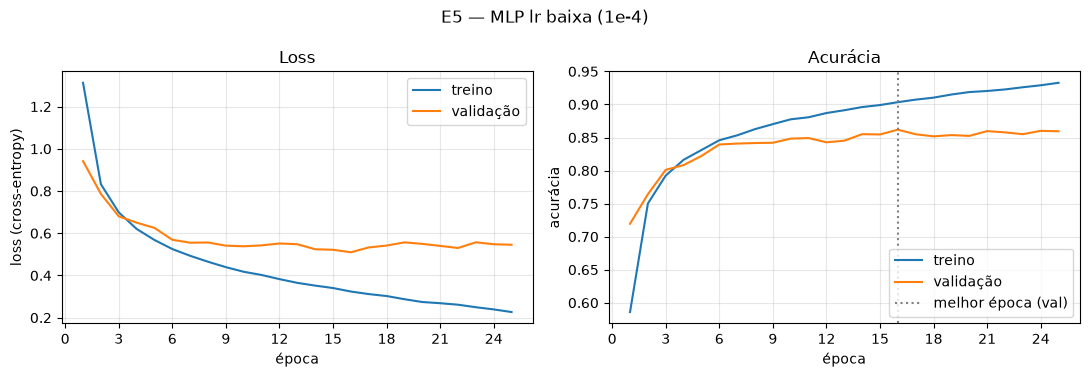

melhor época 16: train_loss=0.3240 val_loss=0.5100 | train_acc=0.9035 val_acc=0.8619 | test_acc=0.8345 | 4.0 min


In [12]:
run(5, 'MLP lr baixa (1e-4)', 'E3 com lr = 1e-4',
    lambda: L.MLP([500, 500]), dados='norm', pai=3,
    epochs=25, batch_size=100, lr=1e-4);

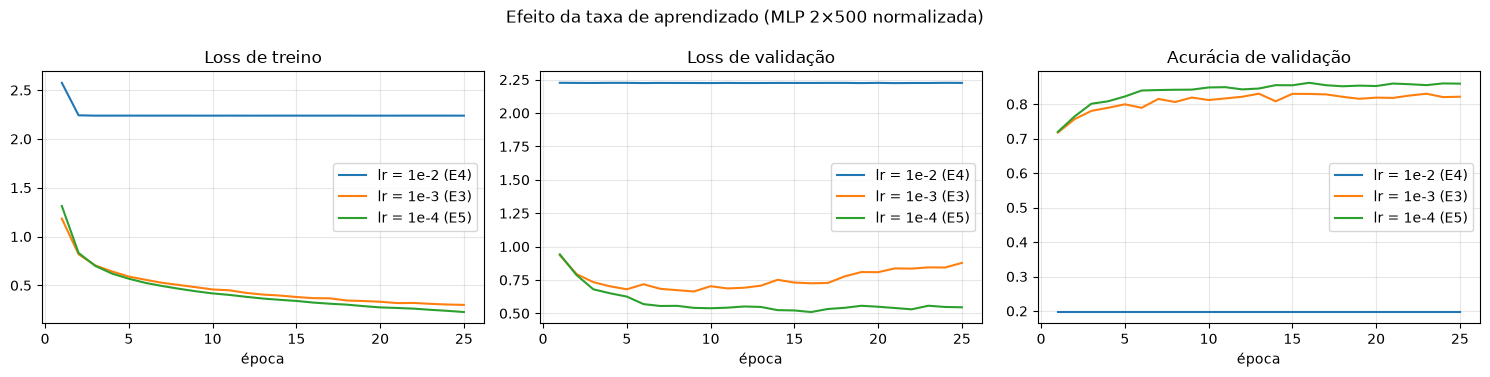

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for e, lr in [(4, '1e-2'), (3, '1e-3'), (5, '1e-4')]:
    h = json.load(open(f'resultados/E{e}.json'))['hist']
    ep = range(1, len(h['val_acc']) + 1)
    ax[0].plot(ep, h['train_loss'], label=f'lr = {lr} (E{e})')
    ax[1].plot(ep, h['val_loss'], label=f'lr = {lr} (E{e})')
    ax[2].plot(ep, h['val_acc'], label=f'lr = {lr} (E{e})')
ax[0].set(title='Loss de treino', xlabel='época'); ax[1].set(title='Loss de validação', xlabel='época')
ax[2].set(title='Acurácia de validação', xlabel='época')
for a in ax: a.grid(alpha=.3); a.legend()
plt.suptitle('Efeito da taxa de aprendizado (MLP 2×500 normalizada)'); plt.tight_layout()
plt.savefig('resultados/comparacao_lr.png', dpi=130); plt.show()

**Qual taxa de aprendizado seguir usando?** Os próximos experimentos partem do melhor dos três (E3, E4, E5)
segundo a acurácia de validação. A escolha é feita pelo código, não à mão.

In [14]:
def melhor(*exps):
    return max((r for r in RESULTS if r['exp'] in exps), key=lambda r: r['val_acc'])

B_LR = melhor(3, 4, 5)
LR = B_LR['config']['lr']
print(f"Melhor taxa na validação: lr = {LR:g} (E{B_LR['exp']}, val_acc = {B_LR['val_acc']:.4f}).")
print(f"Os próximos experimentos partem do E{B_LR['exp']}.")

Melhor taxa na validação: lr = 0.0001 (E5, val_acc = 0.8619).
Os próximos experimentos partem do E5.


### E6 — mais camadas e neurônios (1024 → 512 → 256)

=== E6: MLP maior ===


época  1/25 | treino loss 1.2924 acc 0.5825 | val loss 0.9389 acc 0.7146 | 15.9s


época  2/25 | treino loss 0.8064 acc 0.7548 | val loss 0.7744 acc 0.7639 | 16.8s


época  3/25 | treino loss 0.6724 acc 0.7974 | val loss 0.6760 acc 0.7998 | 20.2s


época  4/25 | treino loss 0.5910 acc 0.8238 | val loss 0.6172 acc 0.8204 | 17.3s


época  5/25 | treino loss 0.5349 acc 0.8390 | val loss 0.6137 acc 0.8209 | 18.6s


... (16 outputs left out)

época 22/25 | treino loss 0.1822 acc 0.9447 | val loss 0.5817 acc 0.8616 | 18.5s


época 23/25 | treino loss 0.1696 acc 0.9477 | val loss 0.6304 acc 0.8514 | 17.1s


época 24/25 | treino loss 0.1561 acc 0.9525 | val loss 0.6007 acc 0.8623 | 18.4s


época 25/25 | treino loss 0.1477 acc 0.9551 | val loss 0.6341 acc 0.8565 | 17.5s


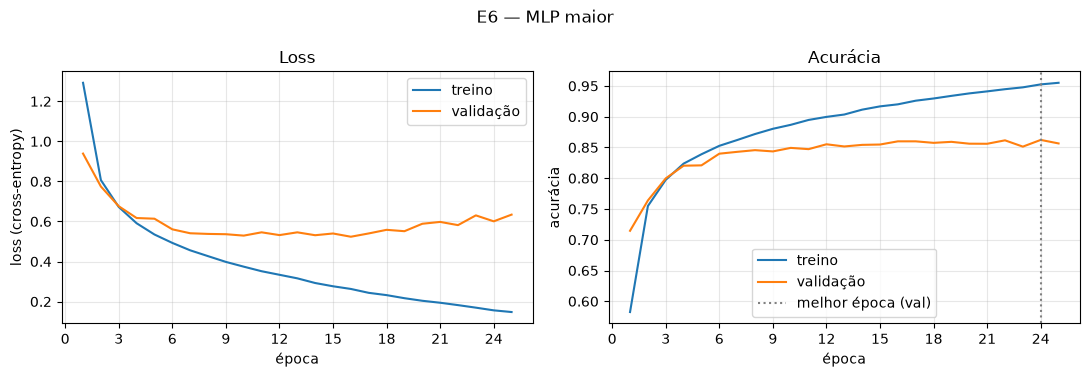

melhor época 24: train_loss=0.1561 val_loss=0.6007 | train_acc=0.9525 val_acc=0.8623 | test_acc=0.8357 | 7.6 min


In [15]:
run(6, 'MLP maior', f"E{B_LR['exp']} com 3 camadas ocultas: 1024-512-256",
    lambda: L.MLP([1024, 512, 256]), dados='norm', pai=B_LR['exp'],
    epochs=25, batch_size=100, lr=LR);

### E7 — E6 + Dropout 0,3
Regularização vista em aula: a cada passo de treino, 30% dos neurônios de cada camada oculta são zerados.

=== E7: MLP + dropout ===


época  1/25 | treino loss 1.5927 acc 0.4588 | val loss 1.0810 acc 0.6626 | 19.6s


época  2/25 | treino loss 1.0240 acc 0.6819 | val loss 0.8438 acc 0.7468 | 19.2s


época  3/25 | treino loss 0.8712 acc 0.7313 | val loss 0.7432 acc 0.7781 | 19.5s


época  4/25 | treino loss 0.7802 acc 0.7629 | val loss 0.6793 acc 0.7968 | 19.7s


época  5/25 | treino loss 0.7271 acc 0.7785 | val loss 0.6596 acc 0.8014 | 19.5s


... (16 outputs left out)

época 22/25 | treino loss 0.4277 acc 0.8659 | val loss 0.4507 acc 0.8643 | 19.7s


época 23/25 | treino loss 0.4231 acc 0.8684 | val loss 0.4438 acc 0.8691 | 20.6s


época 24/25 | treino loss 0.4095 acc 0.8730 | val loss 0.4466 acc 0.8645 | 23.0s


época 25/25 | treino loss 0.4071 acc 0.8736 | val loss 0.4484 acc 0.8649 | 19.3s


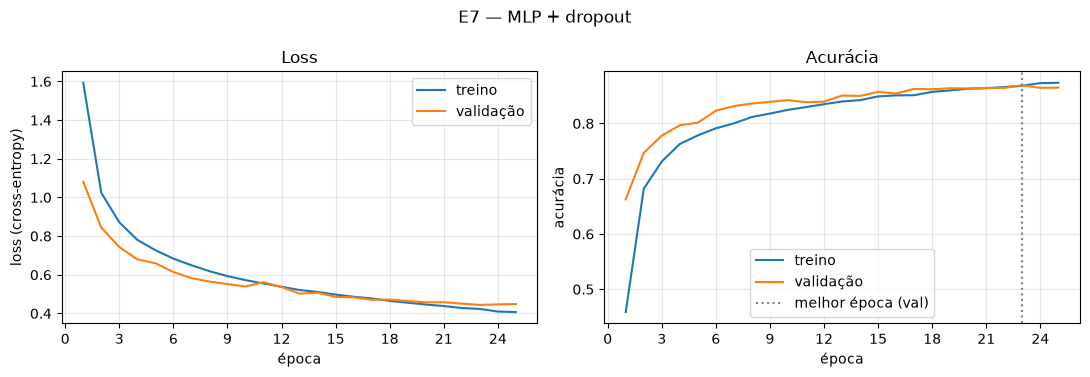

melhor época 23: train_loss=0.4231 val_loss=0.4438 | train_acc=0.8684 val_acc=0.8691 | test_acc=0.8455 | 8.6 min


In [16]:
run(7, 'MLP + dropout', 'E6 + dropout 0,3',
    lambda: L.MLP([1024, 512, 256], dropout=0.3), dados='norm', pai=6,
    epochs=25, batch_size=100, lr=LR);

### E8 — E7 + Batch Normalization
Normaliza as ativações de cada camada oculta dentro do mini-batch (a mesma ideia da normalização da entrada,
aplicada dentro da rede).

=== E8: MLP + dropout + BN ===


época  1/25 | treino loss 1.6308 acc 0.4584 | val loss 1.1020 acc 0.6723 | 23.5s


época  2/25 | treino loss 1.0991 acc 0.6572 | val loss 0.8784 acc 0.7312 | 20.6s


época  3/25 | treino loss 0.9358 acc 0.7064 | val loss 0.7397 acc 0.7733 | 20.8s


época  4/25 | treino loss 0.8486 acc 0.7343 | val loss 0.6665 acc 0.7962 | 24.0s


época  5/25 | treino loss 0.7949 acc 0.7525 | val loss 0.6395 acc 0.8078 | 20.6s


... (16 outputs left out)

época 22/25 | treino loss 0.5010 acc 0.8413 | val loss 0.4289 acc 0.8687 | 23.2s


época 23/25 | treino loss 0.4946 acc 0.8431 | val loss 0.4344 acc 0.8649 | 20.8s


época 24/25 | treino loss 0.4837 acc 0.8471 | val loss 0.4249 acc 0.8702 | 19.6s


época 25/25 | treino loss 0.4823 acc 0.8467 | val loss 0.4428 acc 0.8631 | 21.1s


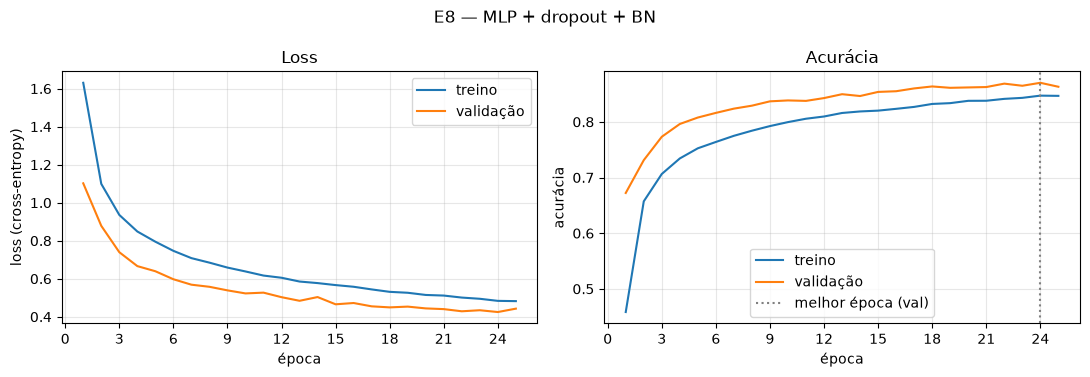

melhor época 24: train_loss=0.4837 val_loss=0.4249 | train_acc=0.8471 val_acc=0.8702 | test_acc=0.8440 | 9.0 min


In [17]:
run(8, 'MLP + dropout + BN', 'E7 + BatchNorm',
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm', pai=7,
    epochs=25, batch_size=100, lr=LR);

### E9 — E8 com a outra taxa de aprendizado
A BatchNorm muda a escala das ativações e costuma permitir taxas maiores, então a taxa escolhida antes (sem BN)
pode não ser mais a melhor. Repetimos o E8 trocando só a taxa (1e-3 ↔ 1e-4) e seguimos com a melhor das duas.

=== E9: MLP + BN, lr 0.001 ===


época  1/25 | treino loss 1.4742 acc 0.5025 | val loss 0.9965 acc 0.6908 | 20.2s


época  2/25 | treino loss 1.0217 acc 0.6741 | val loss 0.7976 acc 0.7517 | 20.5s


época  3/25 | treino loss 0.8761 acc 0.7218 | val loss 0.7121 acc 0.7789 | 22.3s


época  4/25 | treino loss 0.8076 acc 0.7451 | val loss 0.6483 acc 0.7993 | 22.1s


época  5/25 | treino loss 0.7506 acc 0.7625 | val loss 0.6186 acc 0.8108 | 20.6s


... (16 outputs left out)

época 22/25 | treino loss 0.4675 acc 0.8503 | val loss 0.4392 acc 0.8624 | 20.8s


época 23/25 | treino loss 0.4599 acc 0.8533 | val loss 0.4292 acc 0.8701 | 23.8s


época 24/25 | treino loss 0.4487 acc 0.8579 | val loss 0.4350 acc 0.8643 | 20.6s


época 25/25 | treino loss 0.4436 acc 0.8580 | val loss 0.4409 acc 0.8625 | 19.4s


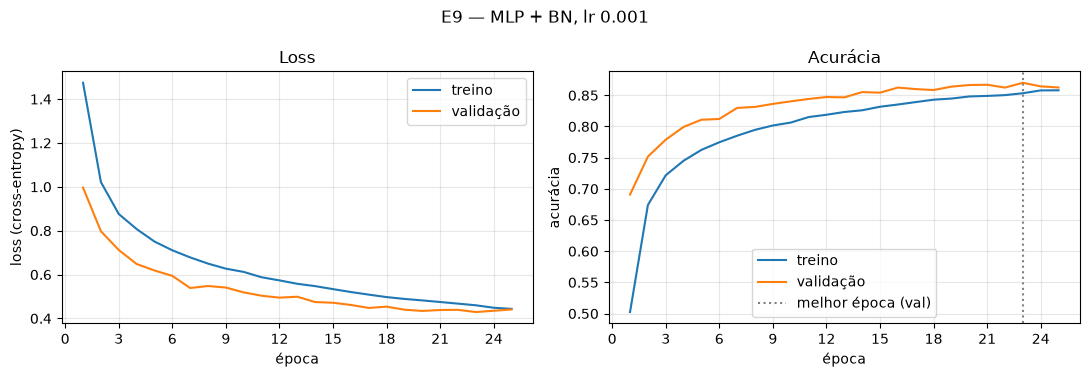

melhor época 23: train_loss=0.4599 val_loss=0.4292 | train_acc=0.8533 val_acc=0.8701 | test_acc=0.8439 | 8.9 min

Com BatchNorm, a melhor taxa na validação é lr = 0.0001 (E8). Seguimos a partir dele.


In [18]:
LR_ALT = 1e-3 if LR != 1e-3 else 1e-4
run(9, f'MLP + BN, lr {LR_ALT:g}', f'E8 com lr = {LR_ALT:g}',
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm', pai=8,
    epochs=25, batch_size=100, lr=LR_ALT);
B_BN = melhor(8, 9)
print(f"\nCom BatchNorm, a melhor taxa na validação é lr = {B_BN['config']['lr']:g} (E{B_BN['exp']}). Seguimos a partir dele.")

### E10 — batch 256 (em vez de 100)
Batch maior: gradiente menos ruidoso, mas menos atualizações por época.

=== E10: MLP batch 256 ===


época  1/25 | treino loss 1.7400 acc 0.4213 | val loss 1.1906 acc 0.6755 | 16.5s


época  2/25 | treino loss 1.1487 acc 0.6512 | val loss 0.8970 acc 0.7452 | 15.1s


época  3/25 | treino loss 0.9601 acc 0.7049 | val loss 0.7720 acc 0.7670 | 17.0s


época  4/25 | treino loss 0.8512 acc 0.7361 | val loss 0.6986 acc 0.7887 | 15.5s


época  5/25 | treino loss 0.7906 acc 0.7523 | val loss 0.6480 acc 0.8045 | 15.6s


... (16 outputs left out)

época 22/25 | treino loss 0.4862 acc 0.8466 | val loss 0.4336 acc 0.8640 | 17.9s


época 23/25 | treino loss 0.4721 acc 0.8510 | val loss 0.4307 acc 0.8699 | 15.3s


época 24/25 | treino loss 0.4641 acc 0.8534 | val loss 0.4411 acc 0.8631 | 15.6s


época 25/25 | treino loss 0.4646 acc 0.8530 | val loss 0.4411 acc 0.8631 | 15.7s


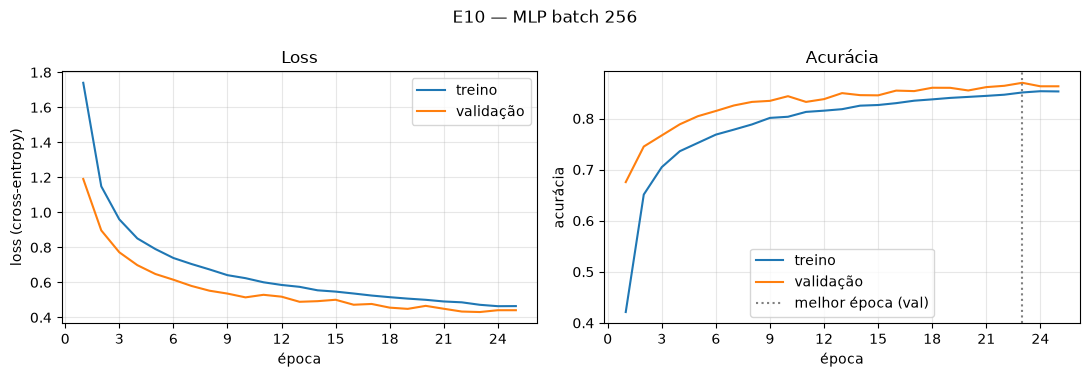

melhor época 23: train_loss=0.4721 val_loss=0.4307 | train_acc=0.8510 val_acc=0.8699 | test_acc=0.8398 | 6.6 min

Melhor tamanho de batch na validação: 100 (E8). Seguimos a partir dele.


In [19]:
run(10, 'MLP batch 256', f"E{B_BN['exp']} com batch 256",
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm', pai=B_BN['exp'],
    **dict(B_BN['config'], batch_size=256));
B_BATCH = melhor(B_BN['exp'], 10)
print(f"\nMelhor tamanho de batch na validação: {B_BATCH['config']['batch_size']} (E{B_BATCH['exp']}). Seguimos a partir dele.")

### E11 — taxa de aprendizado com decaimento cosseno
A taxa começa no valor escolhido e cai suavemente até zero: passos grandes no início e ajuste fino no fim.

=== E11: MLP + lr cosseno ===


época  1/25 | treino loss 1.6308 acc 0.4584 | val loss 1.1020 acc 0.6723 | 23.4s


época  2/25 | treino loss 1.0966 acc 0.6580 | val loss 0.8768 acc 0.7281 | 20.7s


época  3/25 | treino loss 0.9327 acc 0.7070 | val loss 0.7446 acc 0.7730 | 21.5s


época  4/25 | treino loss 0.8467 acc 0.7335 | val loss 0.6651 acc 0.7968 | 20.7s


época  5/25 | treino loss 0.7929 acc 0.7512 | val loss 0.6308 acc 0.8112 | 23.8s


... (16 outputs left out)

época 22/25 | treino loss 0.4461 acc 0.8590 | val loss 0.4039 acc 0.8747 | 20.5s


época 23/25 | treino loss 0.4421 acc 0.8614 | val loss 0.4042 acc 0.8767 | 24.3s


época 24/25 | treino loss 0.4352 acc 0.8642 | val loss 0.4009 acc 0.8778 | 22.0s


época 25/25 | treino loss 0.4382 acc 0.8636 | val loss 0.4029 acc 0.8762 | 20.6s


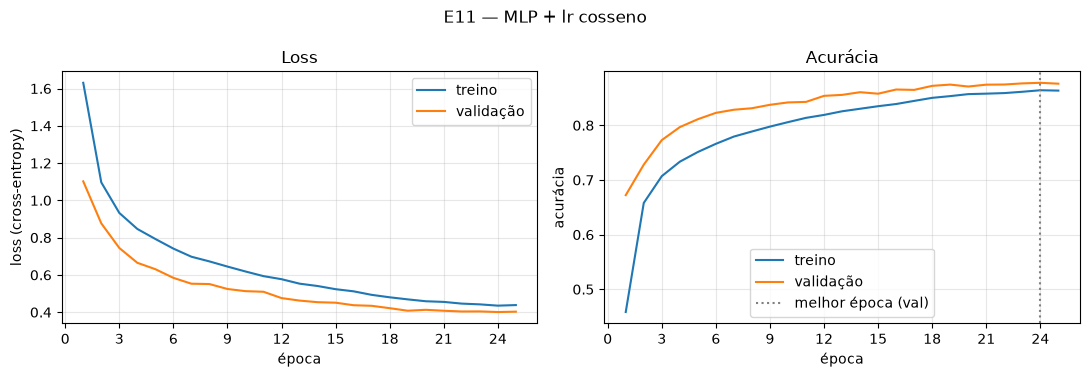

melhor época 24: train_loss=0.4352 val_loss=0.4009 | train_acc=0.8642 val_acc=0.8778 | test_acc=0.8546 | 9.0 min

Melhor MLP na validação: E11 — MLP + lr cosseno (val_acc = 0.8778, test_acc = 0.8546)


In [20]:
run(11, 'MLP + lr cosseno', f"E{B_BATCH['exp']} + decaimento cosseno da lr",
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm', pai=B_BATCH['exp'],
    **dict(B_BATCH['config'], scheduler='cosine'));
B_MLP = melhor(*range(2, 12))
print(f"\nMelhor MLP na validação: E{B_MLP['exp']} — {B_MLP['nome']} (val_acc = {B_MLP['val_acc']:.4f}, test_acc = {B_MLP['test_acc']:.4f})")

### E12 — CNN (rede convolucional)
O enunciado deixa a arquitetura livre e cita o "número de filtros". A MLP trata cada pixel como uma entrada
independente; a convolução aplica os mesmos filtros em toda a imagem e aproveita a vizinhança dos pixels.
Arquitetura: 3 blocos convolucionais (32 → 64 → 128 filtros 3×3, BatchNorm, ReLU, max-pool) e um classificador
totalmente conectado com dropout 0,3. Treino: Adam, lr 1e-3 com decaimento cosseno, batch 128, 20 épocas.

=== E12: CNN ===


época  1/20 | treino loss 1.0688 acc 0.6366 | val loss 0.3896 acc 0.8814 | 157.9s


época  2/20 | treino loss 0.4394 acc 0.8672 | val loss 0.3032 acc 0.9124 | 157.9s


época  3/20 | treino loss 0.3599 acc 0.8933 | val loss 0.2622 acc 0.9249 | 163.0s


época  4/20 | treino loss 0.3137 acc 0.9102 | val loss 0.2517 acc 0.9271 | 159.9s


época  5/20 | treino loss 0.2723 acc 0.9216 | val loss 0.2229 acc 0.9358 | 162.1s


... (11 outputs left out)

época 17/20 | treino loss 0.0617 acc 0.9812 | val loss 0.2336 acc 0.9522 | 158.5s


época 18/20 | treino loss 0.0569 acc 0.9833 | val loss 0.2343 acc 0.9543 | 158.5s


época 19/20 | treino loss 0.0530 acc 0.9845 | val loss 0.2350 acc 0.9545 | 164.4s


época 20/20 | treino loss 0.0529 acc 0.9844 | val loss 0.2361 acc 0.9541 | 159.9s


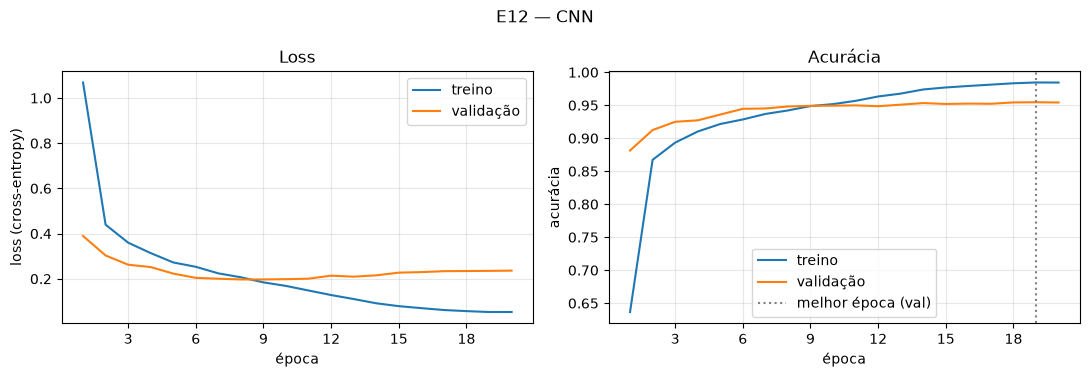

melhor época 19: train_loss=0.0530 val_loss=0.2350 | train_acc=0.9845 val_acc=0.9545 | test_acc=0.9517 | 53.8 min


In [21]:
run(12, 'CNN', 'CNN 3 blocos conv (32-64-128 filtros)',
    lambda: L.CNN(dropout=0.3), dados='norm', pai=B_MLP['exp'],
    epochs=20, batch_size=128, lr=1e-3, scheduler='cosine');

### E13 — E12 + data augmentation
Translação aleatória de até 2 pixels em cada imagem de treino. Não usamos espelhamento horizontal, que muda o
significado de alguns dígitos.

=== E13: CNN + augmentation ===


época  1/20 | treino loss 1.0142 acc 0.6578 | val loss 0.3436 acc 0.8908 | 155.1s


época  2/20 | treino loss 0.4521 acc 0.8649 | val loss 0.2801 acc 0.9146 | 161.6s


época  3/20 | treino loss 0.3769 acc 0.8898 | val loss 0.2445 acc 0.9275 | 165.6s


época  4/20 | treino loss 0.3322 acc 0.9051 | val loss 0.2255 acc 0.9341 | 162.4s


época  5/20 | treino loss 0.2981 acc 0.9167 | val loss 0.2210 acc 0.9346 | 160.3s


... (11 outputs left out)

época 17/20 | treino loss 0.1362 acc 0.9648 | val loss 0.1638 acc 0.9574 | 162.3s


época 18/20 | treino loss 0.1298 acc 0.9670 | val loss 0.1631 acc 0.9570 | 162.3s


época 19/20 | treino loss 0.1246 acc 0.9679 | val loss 0.1616 acc 0.9580 | 158.2s


época 20/20 | treino loss 0.1229 acc 0.9685 | val loss 0.1614 acc 0.9578 | 154.9s


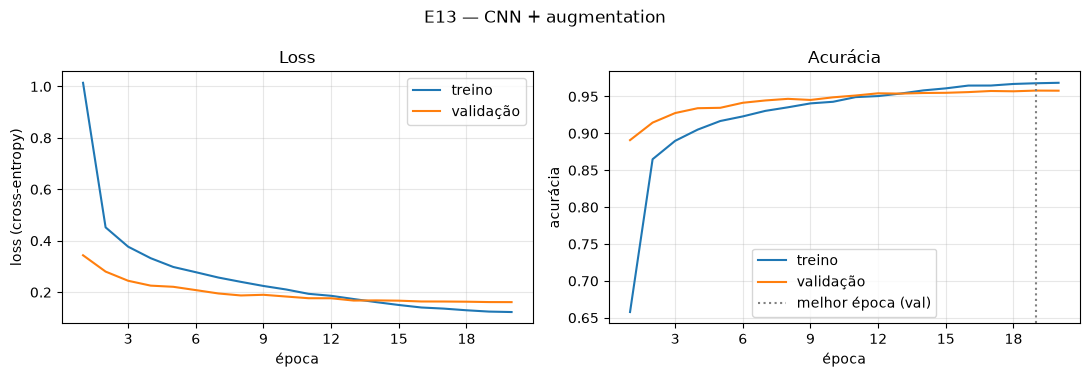

melhor época 19: train_loss=0.1246 val_loss=0.1616 | train_acc=0.9679 val_acc=0.9580 | test_acc=0.9627 | 54.3 min


In [22]:
run(13, 'CNN + augmentation', 'E12 + translação aleatória de ±2 px',
    lambda: L.CNN(dropout=0.3), dados='norm', pai=12,
    epochs=20, batch_size=128, lr=1e-3, scheduler='cosine', augment_shift=2);

### De volta à MLP: E14 a E17

O modelo final precisa ser uma rede totalmente conectada, então os próximos experimentos voltam à melhor MLP e
tentam aproximá-la da CNN. A CNN ganha da MLP porque já "sabe" que um dígito deslocado é o mesmo dígito; a MLP
precisa aprender isso com os dados.

### E14 — melhor MLP + data augmentation
A mesma translação aleatória de ±2 px do E13, agora na melhor MLP. Para a MLP, cada imagem deslocada é um exemplo
novo.

=== E14: MLP + augmentation ===


época  1/25 | treino loss 1.8652 acc 0.3599 | val loss 1.2026 acc 0.6548 | 21.0s


época  2/25 | treino loss 1.3593 acc 0.5588 | val loss 0.9167 acc 0.7290 | 23.7s


época  3/25 | treino loss 1.1679 acc 0.6234 | val loss 0.7932 acc 0.7615 | 21.1s


época  4/25 | treino loss 1.0602 acc 0.6607 | val loss 0.6841 acc 0.7987 | 21.4s


época  5/25 | treino loss 0.9893 acc 0.6832 | val loss 0.6941 acc 0.7865 | 21.2s


... (16 outputs left out)

época 22/25 | treino loss 0.6296 acc 0.8025 | val loss 0.4039 acc 0.8773 | 22.6s


época 23/25 | treino loss 0.6290 acc 0.8016 | val loss 0.4017 acc 0.8780 | 22.1s


época 24/25 | treino loss 0.6227 acc 0.8036 | val loss 0.4008 acc 0.8784 | 21.4s


época 25/25 | treino loss 0.6224 acc 0.8032 | val loss 0.4012 acc 0.8767 | 21.5s


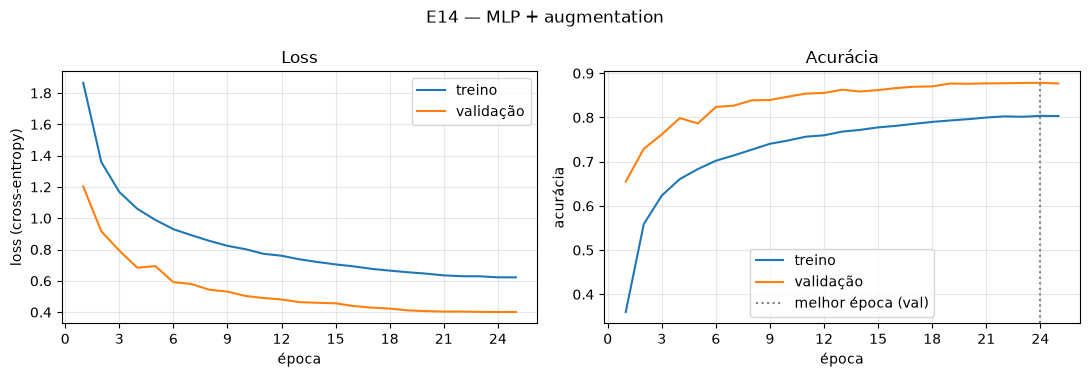

melhor época 24: train_loss=0.6227 val_loss=0.4008 | train_acc=0.8036 val_acc=0.8784 | test_acc=0.8621 | 9.2 min

Acurácia de treino (0.8036) x validação (0.8784) na melhor época.


In [23]:
run(14, 'MLP + augmentation', f"E{B_MLP['exp']} + translação aleatória de ±2 px",
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm', pai=B_MLP['exp'],
    **dict(B_MLP['config'], augment_shift=2));
r14 = RESULTS[-1]
print(f"\nAcurácia de treino ({r14['train_acc']:.4f}) x validação ({r14['val_acc']:.4f}) na melhor época.")

### E15 — rede maior e treino mais longo
Com dropout e augmentation, a acurácia de treino do E14 fica **abaixo** da de validação: a rede não está
decorando o treino, está faltando capacidade e tempo de treino (underfitting). Por isso este experimento muda o
"tamanho" do treino como um todo: 4 camadas ocultas de 2048 neurônios, dropout menor (0,1), 60 épocas e taxa de
aprendizado maior (1e-3) com a política *one-cycle* (sobe nos primeiros 10% dos passos e depois decai até quase
zero), otimizador AdamW e batch 128. São várias mudanças juntas, todas na mesma direção (mais capacidade e menos
regularização); o efeito medido é o do conjunto.

=== E15: MLP grande ===


época  1/60 | treino loss 1.4838 acc 0.5043 | val loss 0.9822 acc 0.6900 | 103.6s


época  2/60 | treino loss 1.1085 acc 0.6429 | val loss 0.8341 acc 0.7408 | 95.6s


época  3/60 | treino loss 0.9957 acc 0.6825 | val loss 1.1096 acc 0.6583 | 88.0s


época  4/60 | treino loss 0.9351 acc 0.7017 | val loss 0.8516 acc 0.7290 | 95.4s


época  5/60 | treino loss 0.8811 acc 0.7204 | val loss 0.7534 acc 0.7632 | 95.6s


... (51 outputs left out)

época 57/60 | treino loss 0.1466 acc 0.9533 | val loss 0.2781 acc 0.9208 | 89.1s


época 58/60 | treino loss 0.1453 acc 0.9541 | val loss 0.2776 acc 0.9211 | 87.8s


época 59/60 | treino loss 0.1460 acc 0.9540 | val loss 0.2802 acc 0.9218 | 86.7s


época 60/60 | treino loss 0.1461 acc 0.9541 | val loss 0.2793 acc 0.9216 | 87.7s


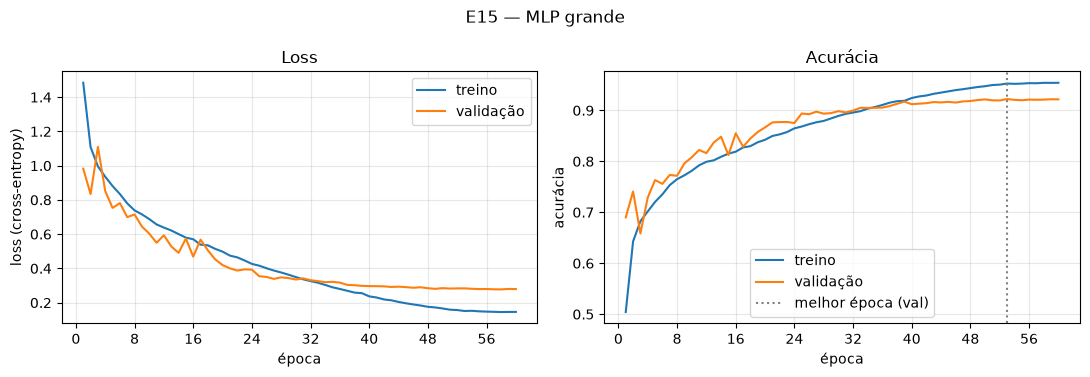

melhor época 53: train_loss=0.1514 val_loss=0.2836 | train_acc=0.9526 val_acc=0.9222 | test_acc=0.9050 | 89.7 min


In [24]:
MLP_G = lambda: L.MLP([2048, 2048, 2048, 2048], dropout=0.1, batchnorm=True)
KW_G = dict(epochs=60, batch_size=128, lr=1e-3, optimizer='adamw', scheduler='onecycle', augment_shift=2)
run(15, 'MLP grande', 'E14 com rede 4×2048, dropout 0,1, 60 épocas, lr 1e-3 one-cycle',
    MLP_G, dados='norm', pai=14, **KW_G);

### E16 — E15 + normalização por imagem
Além da média e do desvio por canal (do treino), cada imagem é normalizada pela sua própria média e desvio. Fotos
escuras, claras ou de baixo contraste passam a ter a mesma faixa de valores.

=== E16: MLP grande + norm. por imagem ===


época  1/60 | treino loss 1.1930 acc 0.6108 | val loss 0.6818 acc 0.7862 | 95.9s


época  2/60 | treino loss 0.8489 acc 0.7295 | val loss 0.6483 acc 0.7993 | 101.8s


época  3/60 | treino loss 0.7836 acc 0.7521 | val loss 0.6299 acc 0.8018 | 89.6s


época  4/60 | treino loss 0.7432 acc 0.7634 | val loss 0.5769 acc 0.8215 | 101.3s


época  5/60 | treino loss 0.7090 acc 0.7754 | val loss 0.5478 acc 0.8272 | 83.6s


... (51 outputs left out)

época 57/60 | treino loss 0.0659 acc 0.9789 | val loss 0.2777 acc 0.9316 | 102.3s


época 58/60 | treino loss 0.0660 acc 0.9798 | val loss 0.2814 acc 0.9304 | 102.4s


época 59/60 | treino loss 0.0649 acc 0.9799 | val loss 0.2859 acc 0.9311 | 100.9s


época 60/60 | treino loss 0.0666 acc 0.9787 | val loss 0.2832 acc 0.9302 | 101.5s


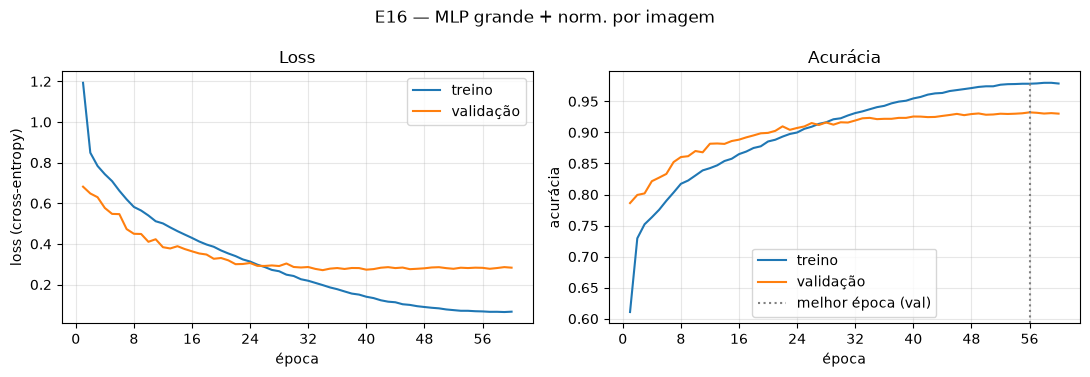

melhor época 56: train_loss=0.0679 val_loss=0.2824 | train_acc=0.9784 val_acc=0.9323 | test_acc=0.9169 | 95.8 min


In [25]:
run(16, 'MLP grande + norm. por imagem', 'E15 + normalização de contraste por imagem',
    MLP_G, dados='norm_img', pai=15, **KW_G);

### E17 — E16 + rotação e escala no augmentation
Além da translação, cada imagem de treino é girada em até ±10° e ampliada ou reduzida em até 10%.

=== E17: MLP grande + rotação/escala ===


época  1/60 | treino loss 1.2383 acc 0.5963 | val loss 0.6845 acc 0.7816 | 96.7s


época  2/60 | treino loss 0.8964 acc 0.7143 | val loss 0.6250 acc 0.8058 | 101.9s


época  3/60 | treino loss 0.8246 acc 0.7364 | val loss 0.5958 acc 0.8134 | 86.9s


época  4/60 | treino loss 0.7783 acc 0.7527 | val loss 0.5527 acc 0.8277 | 103.6s


época  5/60 | treino loss 0.7451 acc 0.7647 | val loss 0.5454 acc 0.8302 | 89.8s


... (51 outputs left out)

época 57/60 | treino loss 0.1012 acc 0.9672 | val loss 0.2612 acc 0.9354 | 102.0s


época 58/60 | treino loss 0.0982 acc 0.9679 | val loss 0.2642 acc 0.9348 | 86.0s


época 59/60 | treino loss 0.0985 acc 0.9687 | val loss 0.2616 acc 0.9339 | 86.4s


época 60/60 | treino loss 0.0997 acc 0.9678 | val loss 0.2636 acc 0.9341 | 90.1s


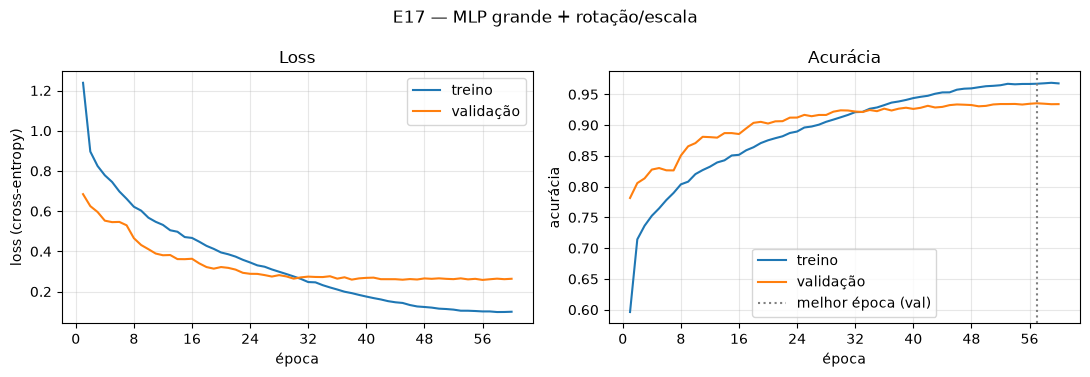

melhor época 57: train_loss=0.1012 val_loss=0.2612 | train_acc=0.9672 val_acc=0.9354 | test_acc=0.9239 | 94.9 min


In [26]:
run(17, 'MLP grande + rotação/escala', 'E16 + rotação ±10° e escala ±10% no augmentation',
    MLP_G, dados='norm_img', pai=16, **dict(KW_G, augment_rot=10.0, augment_scale=0.1));

## 4. Comparação dos experimentos

In [27]:
df = pd.DataFrame(RESULTS).drop(columns=['config'])
df['gap_treino_val'] = df['train_acc'] - df['val_acc']
df.to_csv('resultados/tabela_experimentos.csv', index=False)
fmt = {c: '{:.4f}' for c in ['train_loss', 'val_loss', 'train_acc', 'val_acc', 'test_acc', 'gap_treino_val']}
df.style.format(fmt | {'tempo_min': '{:.1f}', 'params': '{:,}'})

,exp,nome,modificacao,dados,pai,params,epocas,melhor_epoca,train_loss,val_loss,train_acc,val_acc,test_acc,tempo_min,gap_treino_val
0,1,Classificador linear,"Linear 3072→10, SGD + L2",norm,nan,"30,730",20,19,2.1442,2.1536,0.2795,0.2883,0.2402,0.2,-0.0088
1,2,MLP baseline,"MLP 2×500, entrada em [0,1]",bruto,1.000000,"1,792,010",25,17,1.3004,1.3011,0.5719,0.5835,0.5501,12.2,-0.0117
2,3,MLP + normalização,E2 + normalização (média/desvio por canal),norm,2.000000,"1,792,010",25,13,0.4058,0.7073,0.8722,0.8303,0.7948,4.4,0.0418
3,4,MLP lr alta (1e-2),E3 com lr = 1e-2,norm,3.000000,"1,792,010",25,1,2.5749,2.2263,0.1853,0.1970,0.1959,12.0,-0.0116
4,5,MLP lr baixa (1e-4),E3 com lr = 1e-4,norm,3.000000,"1,792,010",25,16,0.3240,0.5100,0.9035,0.8619,0.8345,4.0,0.0416
5,6,MLP maior,E5 com 3 camadas ocultas: 1024-512-256,norm,5.000000,"3,805,450",25,24,0.1561,0.6007,0.9525,0.8623,0.8357,7.6,0.0902
6,7,MLP + dropout,"E6 + dropout 0,3",norm,6.000000,"3,805,450",25,23,0.4231,0.4438,0.8684,0.8691,0.8455,8.6,-0.0007
7,8,MLP + dropout + BN,E7 + BatchNorm,norm,7.000000,"3,809,034",25,24,0.4837,0.4249,0.8471,0.8702,0.8440,9.0,-0.0231
8,9,"MLP + BN, lr 0.001",E8 com lr = 0.001,norm,8.000000,"3,809,034",25,23,0.4599,0.4292,0.8533,0.8701,0.8439,8.9,-0.0167
9,10,MLP batch 256,E8 com batch 256,norm,8.000000,"3,809,034",25,23,0.4721,0.4307,0.8510,0.8699,0.8398,6.6,-0.0189


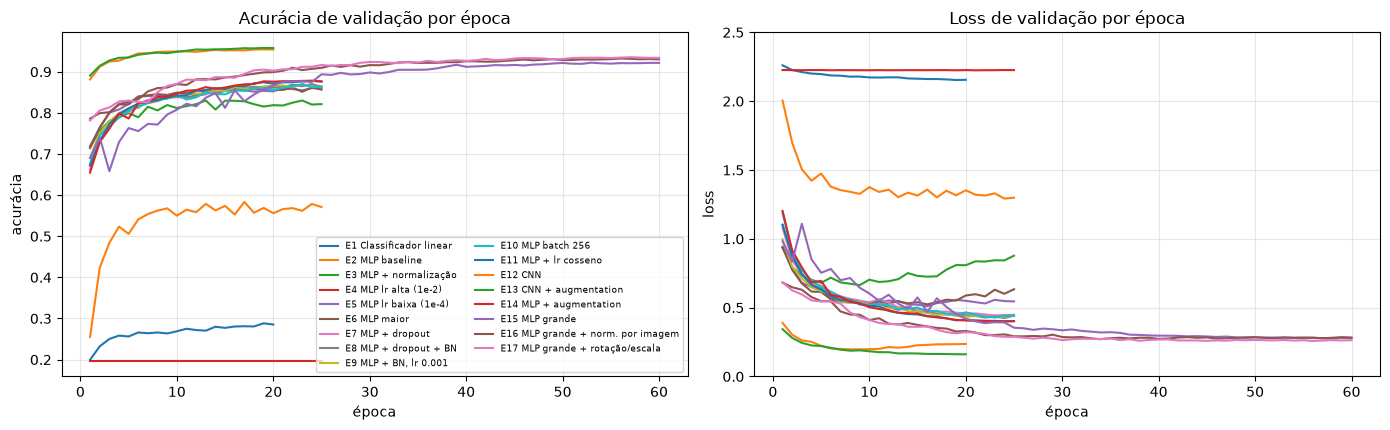

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for r in RESULTS:
    h = json.load(open(f"resultados/E{r['exp']}.json"))['hist']
    ax[0].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], label=f"E{r['exp']} {r['nome']}")
    ax[1].plot(range(1, len(h['val_loss']) + 1), h['val_loss'], label=f"E{r['exp']}")
ax[0].set(title='Acurácia de validação por época', xlabel='época', ylabel='acurácia')
ax[1].set(title='Loss de validação por época', xlabel='época', ylabel='loss', ylim=(0, 2.5))
for a in ax: a.grid(alpha=.3)
ax[0].legend(fontsize=6.5, ncol=2); plt.tight_layout(); plt.savefig('resultados/comparacao_validacao.png', dpi=130); plt.show()

## 5. Escolha do modelo
Escolhemos a MLP com a maior acurácia de validação. A CNN não entra porque o modelo final precisa ser uma MLP.

In [29]:
CNNS = (12, 13)
best = max((r for r in RESULTS if r['exp'] not in CNNS), key=lambda r: r['val_acc'])
cnn = max((r for r in RESULTS if r['exp'] in CNNS), key=lambda r: r['val_acc'])
print(f"Modelo escolhido: E{best['exp']} — {best['nome']}")
print(f"val_acc = {best['val_acc']:.4f} | test_acc = {best['test_acc']:.4f} | melhor época {best['melhor_epoca']} de {best['epocas']}")
print(f"Comparação: a melhor CNN (E{cnn['exp']}) tem val_acc = {cnn['val_acc']:.4f} e test_acc = {cnn['test_acc']:.4f}.")

Modelo escolhido: E17 — MLP grande + rotação/escala
val_acc = 0.9354 | test_acc = 0.9239 | melhor época 57 de 60
Comparação: a melhor CNN (E13) tem val_acc = 0.9580 e test_acc = 0.9627.


### Média sobre translações na predição
A MLP não é invariante a translação. Então, na hora de predizer, passamos cada imagem várias vezes, deslocada de −r
a +r pixels em cada direção, e tiramos a média das probabilidades. Os pesos continuam os mesmos. O raio r foi
escolhido pela validação (r = 0 é a predição normal, r = 1 usa 9 posições e r = 2 usa 25).

In [30]:
make_model, dados_best, kw_best = REGISTRY[best['exp']]
m_best = make_model()
m_best.load_state_dict(torch.load(f"pesos/E{best['exp']}.pt")['state_dict'])
d = DATA[dados_best]
TTA = []
for r in (0, 1, 2):
    va = (L.predict_tta(m_best, d['X_val'], r) == d['y_val']).float().mean().item()
    te = (L.predict_tta(m_best, d['X_test'], r) == d['y_test']).float().mean().item()
    TTA.append(dict(raio=r, n_translacoes=(2 * r + 1) ** 2, val_acc=va, test_acc=te))
    print(f"raio {r} ({(2 * r + 1) ** 2:2d} translações): val_acc = {va:.4f} | test_acc = {te:.4f}")
T_BEST = max(TTA, key=lambda t: t['val_acc'])
TTA_R = T_BEST['raio']
print(f"\nRaio escolhido pela validação: {TTA_R}")
with open('resultados/melhor_modelo.json', 'w') as f:
    json.dump(dict(best, tta=TTA, tta_raio=TTA_R, val_acc_tta=T_BEST['val_acc'], test_acc_tta=T_BEST['test_acc'],
                   arquitetura=m_best.config, cnn=cnn), f, indent=1)

raio 0 ( 1 translações): val_acc = 0.9354 | test_acc = 0.9239


raio 1 ( 9 translações): val_acc = 0.9398 | test_acc = 0.9300


raio 2 (25 translações): val_acc = 0.9432 | test_acc = 0.9348

Raio escolhido pela validação: 2


## 6. Modelo final

O enunciado deixa usar todo o `train` na versão final. Treinamos de novo a configuração escolhida, sem mudar nada
(mesmas épocas, mesma semente, mesmo raio), agora com as 73.257 imagens. Como não tem mais validação, ficamos com
os pesos da última época; no fim do treino a taxa de aprendizado já está perto de zero.

época  1/60 | treino loss 1.2068 acc 0.6041 | 94.4s


época  2/60 | treino loss 0.8679 acc 0.7244 | 100.2s


época  3/60 | treino loss 0.8007 acc 0.7435 | 98.0s


época  4/60 | treino loss 0.7611 acc 0.7583 | 95.6s


época  5/60 | treino loss 0.7215 acc 0.7712 | 97.9s


época  6/60 | treino loss 0.6795 acc 0.7862 | 92.0s


... (51 outputs left out)

época 58/60 | treino loss 0.0929 acc 0.9711 | 101.4s


época 59/60 | treino loss 0.0911 acc 0.9707 | 101.1s


época 60/60 | treino loss 0.0902 acc 0.9718 | 96.9s



Modelo final (E17 retreinado com treino + validação) | 98.2 min
test_acc = 0.9392 com média sobre translações (raio 2) | 0.9283 sem a média
(o mesmo modelo treinado só com 90%: 0.9348 com a média | 0.9239 sem)


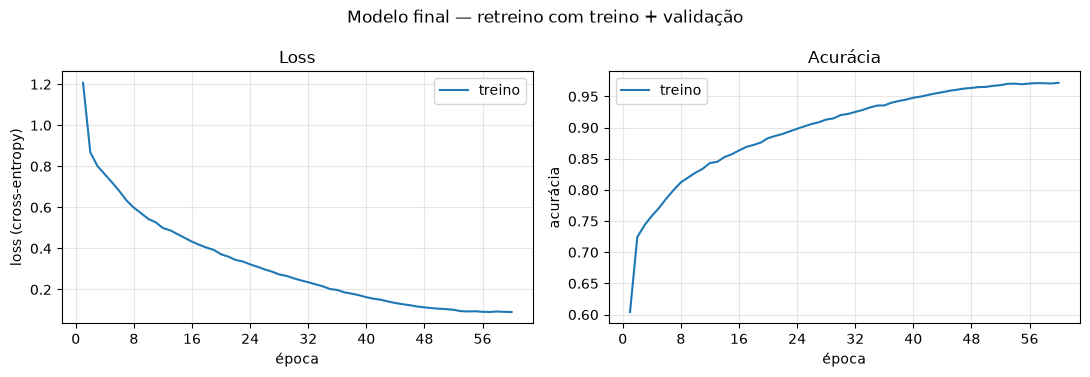

pesos salvos em melhor_modelo.pt


In [31]:
mean_f, std_f = L.compute_norm_stats(X_all)

def prep(X):
    if dados_best == 'bruto':
        return L.preprocess(X)
    Xf = L.preprocess(X, mean_f, std_f)
    return L.per_image_norm(Xf) if dados_best == 'norm_img' else Xf

L.set_seed(SEED)
final_model = make_model()
t0 = time.time()
hist_final = L.train_model(final_model, dict(X_train=prep(X_all), y_train=y_all), seed=SEED, device=device, **kw_best)
X_test_f = prep(X_test_u8)
final_test_loss, acc_sem_tta = L.evaluate(final_model, X_test_f, y_test, device=device)
pred_test = L.predict_tta(final_model, X_test_f, TTA_R, device=device)
final_test_acc = (pred_test == y_test).float().mean().item()
print(f"\nModelo final (E{best['exp']} retreinado com treino + validação) | {(time.time() - t0) / 60:.1f} min")
print(f"test_acc = {final_test_acc:.4f} com média sobre translações (raio {TTA_R}) | {acc_sem_tta:.4f} sem a média")
print(f"(o mesmo modelo treinado só com 90%: {T_BEST['test_acc']:.4f} com a média | {best['test_acc']:.4f} sem)")

torch.save({'exp': best['exp'], 'nome': best['nome'], 'state_dict': final_model.state_dict(),
            'arquitetura': final_model.config, 'mean': mean_f, 'std': std_f, 'dados': dados_best,
            'tta_raio': TTA_R, 'config': kw_best,
            'val_acc_selecao': best['val_acc'], 'test_acc': final_test_acc}, 'melhor_modelo.pt')
with open('resultados/final.json', 'w') as f:
    json.dump({'exp': best['exp'], 'nome': best['nome'], 'n_treino': len(X_all), 'hist': hist_final,
               'test_loss': final_test_loss, 'test_acc': final_test_acc, 'test_acc_sem_tta': acc_sem_tta,
               'tta_raio': TTA_R, 'test_acc_selecao': best['test_acc'], 'val_acc_selecao': best['val_acc']}, f, indent=1)
L.plot_history(hist_final, 'Modelo final — retreino com treino + validação', 'resultados/final_curvas.png'); plt.show()
print('pesos salvos em melhor_modelo.pt')

### Matriz de confusão do modelo final no teste

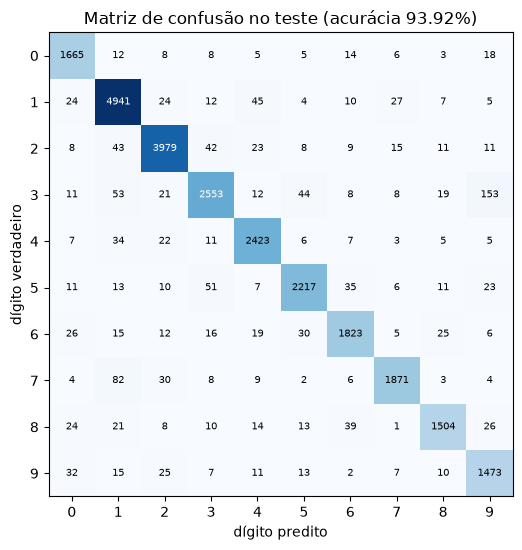

acurácia por dígito: {0: 0.9547, 1: 0.969, 2: 0.959, 3: 0.8858, 4: 0.9604, 5: 0.9299, 6: 0.9221, 7: 0.9267, 8: 0.906, 9: 0.9235}
confusões mais comuns (verdadeiro → predito): [(3, 9, 153), (7, 1, 82), (3, 1, 53), (5, 3, 51), (1, 4, 45)]


In [32]:
cm = L.confusion_matrix(y_test, pred_test)
acc_classe = cm.diag().float() / cm.sum(1).float()

fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(cm, cmap='Blues')
for i in range(10):
    for j in range(10):
        v = int(cm[i, j])
        ax.text(j, i, v, ha='center', va='center', fontsize=7, color='white' if v > cm.max() / 2 else 'black')
ax.set(xticks=range(10), yticks=range(10), xlabel='dígito predito', ylabel='dígito verdadeiro',
       title=f'Matriz de confusão no teste (acurácia {final_test_acc:.2%})')
plt.tight_layout(); plt.savefig('resultados/final_confusao.png', dpi=130); plt.show()

print('acurácia por dígito:', {d: round(float(a), 4) for d, a in enumerate(acc_classe)})
erros = cm.clone(); erros.fill_diagonal_(0)
top = torch.topk(erros.flatten(), 5)
print('confusões mais comuns (verdadeiro → predito):',
      [(int(i) // 10, int(i) % 10, int(v)) for v, i in zip(top.values, top.indices)])
with open('resultados/final_confusao.json', 'w') as f:
    json.dump({'cm': cm.tolist(), 'acc_classe': acc_classe.tolist()}, f)

## 7. Predição do conjunto adicional
Usamos o modelo final com o mesmo pré-processamento e a mesma média sobre translações. As imagens são lidas em
ordem do nome do arquivo e o resultado tem uma predição por linha, na mesma ordem.

As imagens estão em `extra/`.

In [33]:
NOMES = 'JOAOBRITO_SAMYRARRUDA_VALBERCONCEICAO'
PASTA_EXTRA = 'extra'

if os.path.isdir(PASTA_EXTRA):
    nomes_arq, X_extra_u8 = L.load_image_folder(PASTA_EXTRA)
    preds = L.predict_tta(final_model, prep(X_extra_u8), TTA_R, device=device)
    saida = f'{NOMES}_RESULTS.txt'
    L.write_results(preds, saida)
    print(f'{len(preds)} imagens -> {saida}')
    print('primeiros arquivos:', nomes_arq[:5], '... último:', nomes_arq[-1])
    print('distribuição das predições:', np.bincount(preds.numpy(), minlength=10))
else:
    print(f'Pasta {PASTA_EXTRA}/ não encontrada: baixe o conjunto adicional e rode esta célula de novo.')

203856 imagens -> JOAOBRITO_SAMYRARRUDA_VALBERCONCEICAO_RESULTS.txt
primeiros arquivos: ['000000.png', '000001.png', '000002.png', '000003.png', '000004.png'] ... último: 203855.png
distribuição das predições: [20446 22016 20720 20162 20272 20362 20015 19912 19902 20049]
